# 01 — Preprocessing: from raw trial files to tallied psychometric data

**Python port of `seq_preprocess.m` and `sim_preprocess.m`.**

## What this notebook does

Each observer ran two separate experiments:

| Experiment | Folder | What varied |
|---|---|---|
| **Sequential** | `SequentialEffect-main/Data` | the two patches appeared one *after* the other — the test was either **first** or **second** |
| **Simultaneous** | `SpaceOrderEffect-main/Data` | the two patches appeared side by side — the test was either on the **left** or on the **right** |

On every trial the observer saw a **standard** patch and a **test** patch and
judged whether they had the **same** luminance or **different** luminances.
The question the whole project is asking is: *does it matter which of the two
patches came first (or was on the left)?* That is the **order effect**.

The raw data are one line per trial. What the fitting stage needs is instead a
**tally**: for each observer × condition × test position × test luminance, how
many trials were run and how many drew a "same" response. Building that tally
is all this notebook does.

The output is two whitespace-delimited files, `seq_data.txt` and `sim_data.txt`,
in exactly the format described in `00_readme.pdf`:

| # | column | meaning |
|---|---|---|
| 1 | `sub_num` | subject number (1–21) |
| 2 | `sub_code` | subject nickname |
| 3 | `cond` | condition number, 1–4 (the folders on disk are 0–3) |
| 4 | `cond_label` | cosmetic leftover from pilot analyses; unused |
| 5 | `standard` | standard luminance, cd/m² |
| 6 | `test_pos` | position of the **test**: 1 = first/left, 2 = second/right |
| 7 | `test` | test luminance, cd/m² |
| 8 | `total` | number of trials at this test luminance |
| 9 | `same` | number of "same" responses |
| 10 | `diff` | number of "different" responses |


In [1]:
import os
import sys
import numpy as np
import pandas as pd

sys.path.insert(0, os.path.abspath('.'))
import orderfx as O            # the shared helper module that sits next to this notebook

# Root of the project: the folder that contains SequentialEffect-main,
# SpaceOrderEffect-main and this analysis folder.
PROJECT_ROOT = os.path.abspath('..')
SEQ_DATA_ROOT = os.path.join(PROJECT_ROOT, 'data', 'sequential')
SIM_DATA_ROOT = os.path.join(PROJECT_ROOT, 'data', 'simultaneous')

OUTPUT_DIR = os.path.join(os.path.abspath('.'), 'outputs')
os.makedirs(OUTPUT_DIR, exist_ok=True)

print('sequential data :', SEQ_DATA_ROOT, os.path.isdir(SEQ_DATA_ROOT))
print('simultaneous data:', SIM_DATA_ROOT, os.path.isdir(SIM_DATA_ROOT))

sequential data : /sessions/jolly-sweet-hypatia/mnt/Order-effect/order-effect/data/sequential True
simultaneous data: /sessions/jolly-sweet-hypatia/mnt/Order-effect/order-effect/data/simultaneous True


## Step 1 — Who is in the analysis?

Both `Data` folders contain a file called **`Completed Participants`** listing
the observers whose data collection finished. The MATLAB scripts hard-code the
same 21 nicknames in alphabetical order, and the *subject number* written into
the tally file is simply that alphabetical position.

We keep the MATLAB ordering (stored as `orderfx.NAMES`) so that subject numbers
match the existing `seq_data.txt`, `sim_data.txt` and `fit_all.csv`, but we
cross-check it against `Completed Participants` below.

In [2]:
def read_completed(data_root):
    path = os.path.join(data_root, 'Completed Participants')
    with open(path) as fh:
        return [line.strip() for line in fh if line.strip()]

completed_seq = read_completed(SEQ_DATA_ROOT)
completed_sim = read_completed(SIM_DATA_ROOT)

print('completed (sequential)  :', len(completed_seq), 'observers')
print('completed (simultaneous):', len(completed_sim), 'observers')
print()
print('same set of observers in both experiments? ',
      set(completed_seq) == set(completed_sim))
print('matches the hard-coded MATLAB list?        ',
      set(completed_seq) == set(O.NAMES))
print()
print('analysis order (subject number = position in this list):')
print(O.NAMES)

completed (sequential)  : 21 observers
completed (simultaneous): 21 observers

same set of observers in both experiments?  True
matches the hard-coded MATLAB list?         True

analysis order (subject number = position in this list):
['Cap', 'Duck', 'Fit', 'Fox', 'Gren', 'Hero', 'Ike', 'Joke', 'Ken', 'King', 'Kir', 'Kong', 'Link', 'Mac', 'Ness', 'Pit', 'Rob', 'Rock', 'Roy', 'Sam', 'Snake']


## Step 2 — The luminance lookup table

The experiment program specified patches by **8-bit grey level** (0–255), but
perception scales with **luminance**, so every analysis is done in cd/m².
The mapping between the two was measured with a photometer for the specific
grey levels used, and is hard-coded in the MATLAB scripts as a 255-element
lookup vector. Grey levels that never occurred are `NaN`.

Note the two overlapping families of values, e.g. 60 → 26.4 vs 59 → 25.9:
these come from the two different background/gamma settings used across
conditions.

In [3]:
lookup_table = pd.DataFrame(
    [(g, O.LOOKUP[g]) for g in range(256) if not np.isnan(O.LOOKUP[g])],
    columns=['grey level (0-255)', 'luminance (cd/m2)'])

print('standard patch per condition:')
for i, rgb in enumerate(O.STANDARD_RGB, start=1):
    print(f'  condition {i} (folder condition_{i-1}): '
          f'grey {rgb:3d}  ->  {O.LOOKUP[rgb]:5.1f} cd/m2')
print()
lookup_table.T

standard patch per condition:
  condition 1 (folder condition_0): grey  60  ->   26.4 cd/m2
  condition 2 (folder condition_1): grey  30  ->   13.2 cd/m2
  condition 3 (folder condition_2): grey  60  ->   26.4 cd/m2
  condition 4 (folder condition_3): grey  90  ->   39.5 cd/m2



,0,1,2,3,4,5,6,7,8,9,10,11,12,13,14,15,16,17,18
grey level (0-255),20.0,23.0,26.0,30.0,34.0,40.0,45.0,52.0,59.0,60.0,68.0,69.0,78.0,79.0,90.0,91.00,103.0,119.0,136.0
luminance (cd/m2),8.8,10.1,11.4,13.2,14.9,17.6,19.8,22.4,25.9,26.4,29.9,30.3,34.3,34.7,39.5,39.96,45.2,52.3,59.7


## Step 3 — What a raw trial file looks like

Each observer/condition has a file
`<Name>/condition_<k>/Repetition_1/<Name>_condition_<k>_Repetition_1.txt`
with one line per trial:

```
129, 1, 2, 1, RGBA(60, 60, 60, 255), RGBA(0, 0, 0, 160), RGBA(52, 52, 52, 255), RGBA(0, 0, 0, 160)
```

Reading left to right:

1. **`order`** — the trial's presentation order (used only to sort the file);
2. **`std_pos`** — which interval/side held the **standard**: 1 or 2;
3. **`true`** — the objectively correct answer;
4. **`resp`** — the observer's response: **1 = "same"**, **2 = "different"**
   (any other value means no valid response was recorded);
5. **RGBA of the patch in position 1**, then **its background**;
6. **RGBA of the patch in position 2**, then **its background**.

All patches are achromatic (R = G = B), so a single number describes each one.

> *Implementation note.* MATLAB's `readtable` splits this line naively on
> commas, producing 20 columns, and `removevars(...)` then keeps columns
> 1, 2, 3, 4, 6, 10, 14, 18 — the four leading integers plus the **green
> channel** of each RGBA group. Since R = G = B that is exactly the grey level.
> `orderfx.read_raw_trial_file` parses the RGBA groups properly and picks the
> same eight numbers, which is more readable and equally faithful.

In [4]:
example_file = os.path.join(SIM_DATA_ROOT, 'Cap', 'condition_0',
                            'Repetition_1', 'Cap_condition_0_Repetition_1.txt')

print('--- first three raw lines -------------------------------------------')
with open(example_file) as fh:
    for _ in range(3):
        print(fh.readline().rstrip())

print()
print('--- after parsing ---------------------------------------------------')
raw_example = O.read_raw_trial_file(example_file)
print(f'{len(raw_example)} trials')
raw_example.head()

--- first three raw lines -------------------------------------------
129, 1, 2, 1, RGBA(60, 60, 60, 255), RGBA(0, 0, 0, 160), RGBA(52, 52, 52, 255), RGBA(0, 0, 0, 160)
112, 1, 2, 2, RGBA(60, 60, 60, 255), RGBA(0, 0, 0, 160), RGBA(91, 91, 91, 255), RGBA(0, 0, 0, 160)
134, 1, 2, 2, RGBA(60, 60, 60, 255), RGBA(0, 0, 0, 160), RGBA(40, 40, 40, 255), RGBA(0, 0, 0, 160)

--- after parsing ---------------------------------------------------
336 trials


,order,std_pos,true,resp,sqr1,bckg1,sqr2,bckg2
0,129,1,2,1,60,0,52,0
1,112,1,2,2,60,0,91,0
2,134,1,2,2,60,0,40,0
3,287,2,2,2,91,0,60,0
4,210,2,2,2,91,0,60,0


## Step 4 — Turning trials into a tally

Four things happen inside `orderfx.tally_one_file`, mirroring the MATLAB loop:

1. **Sort by `order`** and **keep only valid responses** (`resp` is 1 or 2).
   Trials where the observer failed to respond are dropped.

2. **Convert standard position into test position.** The raw file records where
   the *standard* was; the analysis is organised around where the *test* was.
   With only two positions, `test_pos = 3 - std_pos`.

3. **Split by test position**, then within each split find the distinct test
   luminances and count, for each one, the number of trials and the number of
   "same" responses. If the test was in position 1 its grey level is in the
   `sqr1` column; if in position 2, in `sqr2`.

4. **Drop a split with fewer than four distinct test levels.** The psychometric
   function has three free parameters, so fewer than four points leaves nothing
   to test the fit against. This is the `if nlevels>=4` guard in MATLAB.

Let's watch it happen for one file.

In [5]:
demo = O.read_raw_trial_file(example_file)
demo = demo.sort_values('order', kind='mergesort')
n_all = len(demo)
demo = demo[demo['resp'].isin([1, 2])]
demo['test_pos'] = 3 - demo['std_pos']

print(f'trials in file                 : {n_all}')
print(f'trials with a valid response   : {len(demo)}')
print(f'trials with test in position 1 : {(demo.test_pos == 1).sum()}')
print(f'trials with test in position 2 : {(demo.test_pos == 2).sum()}')
print()

block = demo[demo.test_pos == 1]
tally_demo = (block.groupby('sqr1')
                   .agg(total=('resp', 'size'), same=('resp', lambda r: (r == 1).sum()))
                   .reset_index())
tally_demo['diff'] = tally_demo['total'] - tally_demo['same']
tally_demo['luminance (cd/m2)'] = O.LOOKUP[tally_demo['sqr1'].to_numpy()]
tally_demo['P(same)'] = tally_demo['same'] / tally_demo['total']
print('Cap, condition 1, test on the LEFT:')
tally_demo

trials in file                 : 336
trials with a valid response   : 336
trials with test in position 1 : 168
trials with test in position 2 : 168

Cap, condition 1, test on the LEFT:


,sqr1,total,same,diff,luminance (cd/m2),P(same)
0,40,24,0,24,17.60,0.000000
1,45,24,2,22,19.80,0.083333
2,52,24,16,8,22.40,0.666667
3,60,24,23,1,26.40,0.958333
4,69,24,22,2,30.30,0.916667
5,79,24,15,9,34.70,0.625000
6,91,24,0,24,39.96,0.000000


Read that table top to bottom and the psychometric function is already
visible: `P(same)` is near zero for test luminances far from the standard
(26.4 cd/m²), rises to a peak around the standard, and falls away again. That
inverted-U is what notebook 02 fits.

## Step 5 — Run the preprocessing over every observer and condition

`orderfx.preprocess_task` loops over the 21 observers × 4 conditions, calls the
tallying routine on each raw file, and converts grey levels to cd/m² with the
lookup table.

One robustness fix over the MATLAB version: subject folder names are not
consistently capitalised on disk (`ness` vs `Ness`, `kir` vs `Kir`). MATLAB is
case-sensitive, and `00_readme.pdf` notes that the folders had to be renamed by
hand before the scripts would run. The Python version resolves folder names
case-insensitively, so it works on the repository as downloaded.

In [6]:
seq = O.preprocess_task(SEQ_DATA_ROOT)
sim = O.preprocess_task(SIM_DATA_ROOT)

print(f'sequential  : {len(seq):5d} rows  ({seq.sub_num.nunique()} observers)')
print(f'simultaneous: {len(sim):5d} rows  ({sim.sub_num.nunique()} observers)')
print()
seq.head(14)

sequential  :  1176 rows  (21 observers)
simultaneous:  1176 rows  (21 observers)



,sub_num,sub_code,cond,cond_label,standard,test_pos,test,total,same,diff
0,1,Cap,1,60_vs_60,26.4,1,17.60,24,3,21
1,1,Cap,1,60_vs_60,26.4,1,19.80,24,11,13
2,1,Cap,1,60_vs_60,26.4,1,22.40,24,17,7
3,1,Cap,1,60_vs_60,26.4,1,26.40,24,21,3
4,1,Cap,1,60_vs_60,26.4,1,30.30,24,17,7
5,1,Cap,1,60_vs_60,26.4,1,34.70,24,10,14
6,1,Cap,1,60_vs_60,26.4,1,39.96,24,5,19
7,1,Cap,1,60_vs_60,26.4,2,17.60,24,5,19
8,1,Cap,1,60_vs_60,26.4,2,19.80,24,14,10
9,1,Cap,1,60_vs_60,26.4,2,22.40,24,17,7


### Sanity checks on the tally

In [7]:
for name, df in [('sequential', seq), ('simultaneous', sim)]:
    print(f'--- {name} ---')
    print('  same + diff == total everywhere:',
          bool(((df['same'] + df['diff']) == df['total']).all()))
    print('  trials per test level (unique values):',
          sorted(df['total'].unique()))
    print('  test levels per subject x condition x position:',
          sorted(df.groupby(['sub_num', 'cond', 'test_pos']).size().unique()))
    print('  cells (subject x condition x position):',
          df.groupby(['sub_num', 'cond', 'test_pos']).ngroups)
    print('  total trials:', int(df['total'].sum()))
    print()

--- sequential ---
  same + diff == total everywhere: True
  trials per test level (unique values): [np.int64(24)]
  test levels per subject x condition x position: [np.int64(7)]
  cells (subject x condition x position): 168
  total trials: 28224

--- simultaneous ---
  same + diff == total everywhere: True
  trials per test level (unique values): [np.int64(24)]
  test levels per subject x condition x position: [np.int64(7)]
  cells (subject x condition x position): 168
  total trials: 28224



## Step 6 — Write the intermediate files

Written in exactly the MATLAB whitespace-delimited format so that they are
drop-in replacements for `seq_data.txt` / `sim_data.txt`.

In [8]:
seq_path = os.path.join(OUTPUT_DIR, 'seq_data.txt')
sim_path = os.path.join(OUTPUT_DIR, 'sim_data.txt')

O.write_tally(seq, seq_path)
O.write_tally(sim, sim_path)

# Also save tidy CSVs with headers, which are friendlier for later reuse.
seq.to_csv(os.path.join(OUTPUT_DIR, 'seq_data.csv'), index=False)
sim.to_csv(os.path.join(OUTPUT_DIR, 'sim_data.csv'), index=False)

print('wrote:')
for p in [seq_path, sim_path,
          os.path.join(OUTPUT_DIR, 'seq_data.csv'),
          os.path.join(OUTPUT_DIR, 'sim_data.csv')]:
    print('  ', p)

wrote:
   /sessions/jolly-sweet-hypatia/mnt/Order-effect/order-effect/analysis/outputs/seq_data.txt
   /sessions/jolly-sweet-hypatia/mnt/Order-effect/order-effect/analysis/outputs/sim_data.txt
   /sessions/jolly-sweet-hypatia/mnt/Order-effect/order-effect/analysis/outputs/seq_data.csv
   /sessions/jolly-sweet-hypatia/mnt/Order-effect/order-effect/analysis/outputs/sim_data.csv


## Step 7 — Verification against the MATLAB output

The original `seq_data.txt` and `sim_data.txt` produced by MATLAB are in the
`reference` folder. Since preprocessing is deterministic counting,
the Python output should be **byte-for-byte identical** (modulo line endings).

In [9]:
REFERENCE_DIR = os.path.join(os.path.abspath('.'), 'reference')

def compare_with_matlab(py_df, matlab_file):
    path = os.path.join(REFERENCE_DIR, matlab_file)
    if not os.path.isfile(path):
        print(f'{matlab_file}: not found, skipping comparison')
        return
    ml = O.load_tally(path)
    key = ['sub_num', 'sub_code', 'cond', 'test_pos', 'test']
    merged = py_df.merge(ml, on=key, suffixes=('_py', '_ml'), how='outer',
                         indicator=True)
    print(f'--- {matlab_file} ---')
    print(f'  rows: python {len(py_df)}, matlab {len(ml)}')
    print(f'  rows present in only one of them: {(merged._merge != "both").sum()}')
    for col in ['standard', 'total', 'same', 'diff']:
        d = (merged[col + '_py'] - merged[col + '_ml']).abs().max()
        print(f'  max |difference| in {col:8s}: {d}')
    print()

compare_with_matlab(seq, 'seq_data.txt')
compare_with_matlab(sim, 'sim_data.txt')

--- seq_data.txt ---
  rows: python 1176, matlab 1176
  rows present in only one of them: 0
  max |difference| in standard: 0.0
  max |difference| in total   : 0
  max |difference| in same    : 0
  max |difference| in diff    : 0

--- sim_data.txt ---
  rows: python 1176, matlab 1176
  rows present in only one of them: 0
  max |difference| in standard: 0.0
  max |difference| in total   : 0
  max |difference| in same    : 0
  max |difference| in diff    : 0



## Step 8 — A first look at the data

Before any model fitting, plot the raw proportion of "same" responses for one
observer. Each panel is one condition; blue and light blue are the two test
positions. If there were **no order effect** the two curves would lie on top of
each other. Any horizontal shift between them is a *Type A* effect (the test
looks brighter or dimmer depending on position); any difference in how sharply
they rise and fall is a *Type B* effect (a difference in precision).

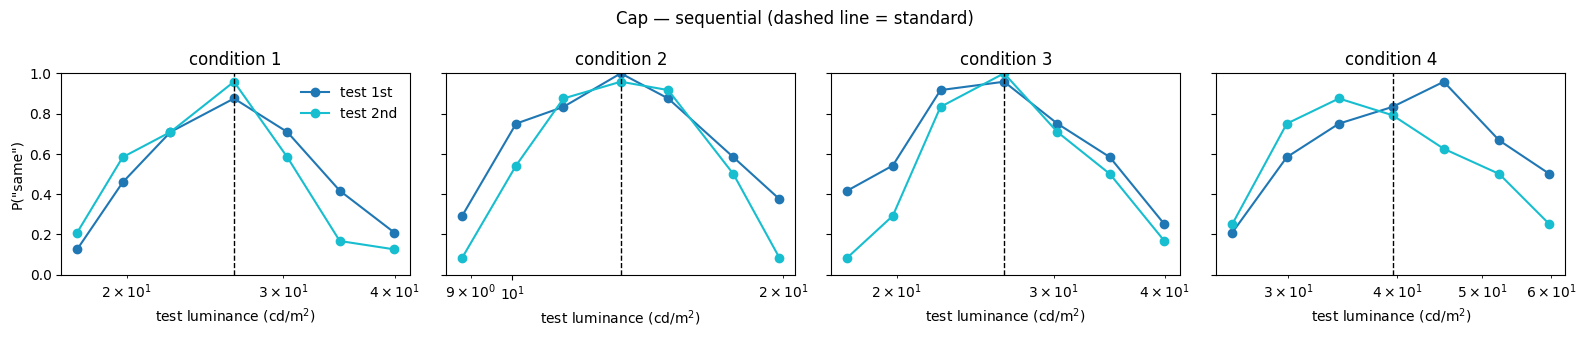

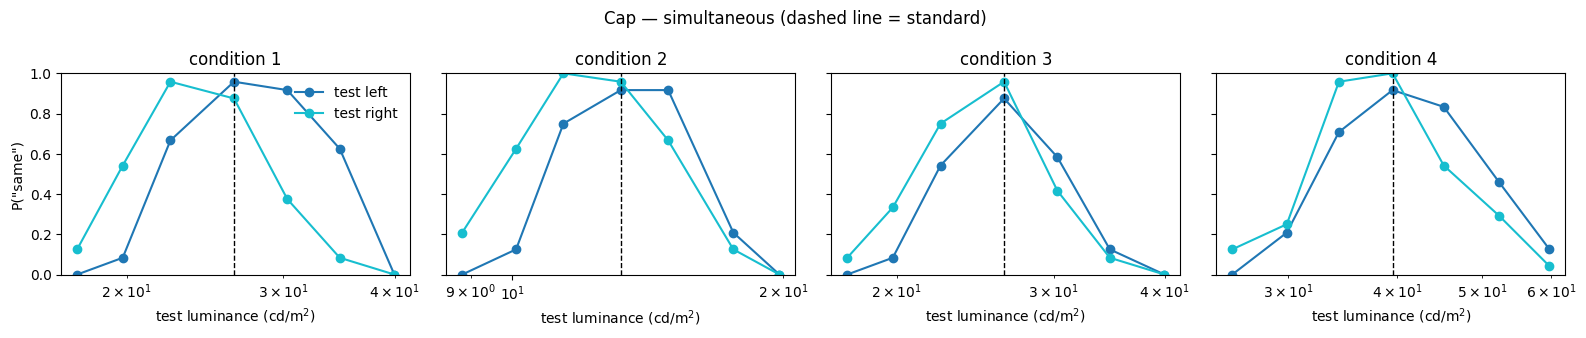

In [10]:
import matplotlib.pyplot as plt

def plot_raw(df, sub, title, labels):
    fig, axes = plt.subplots(1, 4, figsize=(16, 3.4), sharey=True)
    for cond, ax in zip(range(1, 5), axes):
        for pos, colour in zip((1, 2), ['tab:blue', 'tab:cyan']):
            take = df[(df.sub_num == sub) & (df['cond'] == cond)
                      & (df.test_pos == pos)].sort_values('test')
            if take.empty:
                continue
            ax.plot(take['test'], take['same'] / take['total'],
                    'o-', color=colour, label=labels[pos - 1])
        std = df[(df.sub_num == sub) & (df['cond'] == cond)]['standard']
        if len(std):
            ax.axvline(std.iloc[0], color='k', ls='--', lw=1)
        ax.set_xscale('log')
        ax.set_ylim(0, 1)
        ax.set_title(f'condition {cond}')
        ax.set_xlabel('test luminance (cd/m$^2$)')
    axes[0].set_ylabel('P("same")')
    axes[0].legend(frameon=False)
    fig.suptitle(title)
    fig.tight_layout()
    return fig

sub = 1
name = O.NAMES[sub - 1]
plot_raw(seq, sub, f'{name} — sequential (dashed line = standard)', ['test 1st', 'test 2nd'])
plot_raw(sim, sub, f'{name} — simultaneous (dashed line = standard)', ['test left', 'test right'])
plt.show()

---

## Summary

* Raw per-trial files → tallies of "same"/"different" counts per test luminance.
* Grey levels converted to measured luminances (cd/m²).
* The position of the *standard* recoded as the position of the *test*.
* Splits with fewer than four test levels discarded.
* Output written to `outputs/seq_data.txt` and `outputs/sim_data.txt`, verified
  identical to the MATLAB files.

**Next:** `02_fit_psychometric_functions.ipynb` fits a psychometric function to
every subject × condition × test-position cell.